# POC - Filtros FIR pasabanda para ECG con `scipy.signal`

Prueba de concepto de los tres métodos de diseño FIR pedidos en la TS7, sobre la misma plantilla:

- **Ventanas**: `sig.firwin2`
- **Cuadrados mínimos**: `sig.firls`
- **Parks-McClellan-Remez**: `sig.remez`

Los filtros se aplican en forma bidireccional (fase cero), así que cada uno se diseña para la mitad de la plantilla en dB: 0,5 dB de ripple y 20 dB de atenuación por pasada.

In [7]:
from pathlib import Path

import numpy as np
import scipy.signal as sig
import scipy.io as sio
import matplotlib.pyplot as plt

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10, 'axes.grid': True, 'grid.alpha': 0.25})

COL = {'Ventana': '#56B4E9', 'Cuad. mínimos': '#E69F00', 'Parks-McClellan': '#0000FF'}
COL_AUX = '#FFB6C1'

DATA = next(p for p in (Path('../Extra/TS5'), Path('Extra/TS5'), Path('.'))
            if (p / 'ECG_TP4.mat').exists())
fs  = 1000.0  # Hz
ecg = sio.loadmat(str(DATA / 'ECG_TP4.mat'))['ecg_lead'].flatten().astype(float)
t   = np.arange(len(ecg)) / fs

## Plantilla

Pasabanda de 0,5 a 35 Hz, con bandas de stop debajo de 0,1 Hz (deriva de línea de base) y encima de 50 Hz (ruido muscular y de red). Ripple efectivo de 1 dB y atenuación de 40 dB.

In [8]:
nyq_frec   = fs / 2
ripple     = 1    # dB, efectivo (ida y vuelta)
atenuacion = 40   # dB, efectivo (ida y vuelta)

ws1, wp1, wp2, ws2 = 0.1, 0.5, 35.0, 50.0  # Hz

## Diseño

**Ventanas.** `firwin2` muestrea la respuesta ideal (0 en stop, 1 en paso) y la trunca con una ventana de Kaiser con β = 1. El ancho de transición queda fijo por el lóbulo principal, así que hacen falta 7001 coeficientes para la transición inferior de 0,4 Hz.

**Cuadrados mínimos.** `firls` minimiza la energía del error en las bandas indicadas. Si la transición superior (35–50 Hz) queda sin especificar, el sistema queda mal condicionado. Por eso se la define como una rampa lineal de 1 a 0.

**Parks-McClellan.** `remez` minimiza el error máximo (equirriple). Con la transición superior de 15 Hz no converge. Como solo admite valores constantes por banda, se angosta la transición a 35–36 Hz, que sigue cumpliendo la plantilla.

In [9]:
# ventanas
b_win = sig.firwin2(7001, [0, ws1, wp1, wp2, ws2, nyq_frec], [0, 0, 1, 1, 0, 0],
                    window=('kaiser', 1.0), fs=fs)

# cuadrados mínimos: bandas [0, ws1], [wp1, wp2], [wp2, ws2] (rampa 1 -> 0), [ws2, nyq]
b_ls = sig.firls(3501, [0, ws1, wp1, wp2, wp2, ws2, ws2, nyq_frec],
                 [0, 0, 1, 1, 1, 0, 0, 0], fs=fs)

# Parks-McClellan: transición superior angostada a 1 Hz para que converja
# b_pm = sig.remez(3001, [0, ws1, wp1, wp2, 36.0, nyq_frec], [0, 1, 0], fs=fs,
#                  grid_density=16, maxiter=200)

filtros = {'Ventana': b_win, 'Cuad. mínimos': b_ls}
# filtros['Parks-McClellan'] = b_pm
for nombre, b in filtros.items():
    print(f'{nombre:16s} {len(b)} coeficientes, max|b| = {np.abs(b).max():.3f}')

Ventana          7001 coeficientes, max|b| = 0.084
Cuad. mínimos    3501 coeficientes, max|b| = 0.084


## Verificación

Se evalúa la respuesta **efectiva** $|H|^2$ (ida y vuelta) en una grilla densa en la banda baja, donde la transición dura 0,4 Hz.

In [10]:
f_eval = np.concatenate([np.linspace(1e-3, 2, 4000), np.linspace(2, nyq_frec, 8000)[1:]])
H_ef = {}
for nombre, b in filtros.items():
    _, h = sig.freqz(b, worN=f_eval, fs=fs)
    H_ef[nombre] = 20 * np.log10(np.abs(h)**2 + 1e-15)

m_paso = (f_eval >= wp1) & (f_eval <= wp2)
print(f"{'Filtro':16s} {'Ripple [dB]':>12s} {'Aten. <0.1 Hz':>14s} {'Aten. >50 Hz':>13s}  Cumple")
for nombre, H in H_ef.items():
    rip = -H[m_paso].min()
    a1, a2 = -H[f_eval <= ws1].max(), -H[f_eval >= ws2].max()
    ok = rip <= ripple and a1 >= atenuacion and a2 >= atenuacion
    print(f'{nombre:16s} {rip:12.2f} {a1:14.1f} {a2:13.1f}  {"sí" if ok else "NO"}')

Filtro            Ripple [dB]  Aten. <0.1 Hz  Aten. >50 Hz  Cumple
Ventana                  0.82           51.0         117.6  sí
Cuad. mínimos            0.64           48.3         108.6  sí


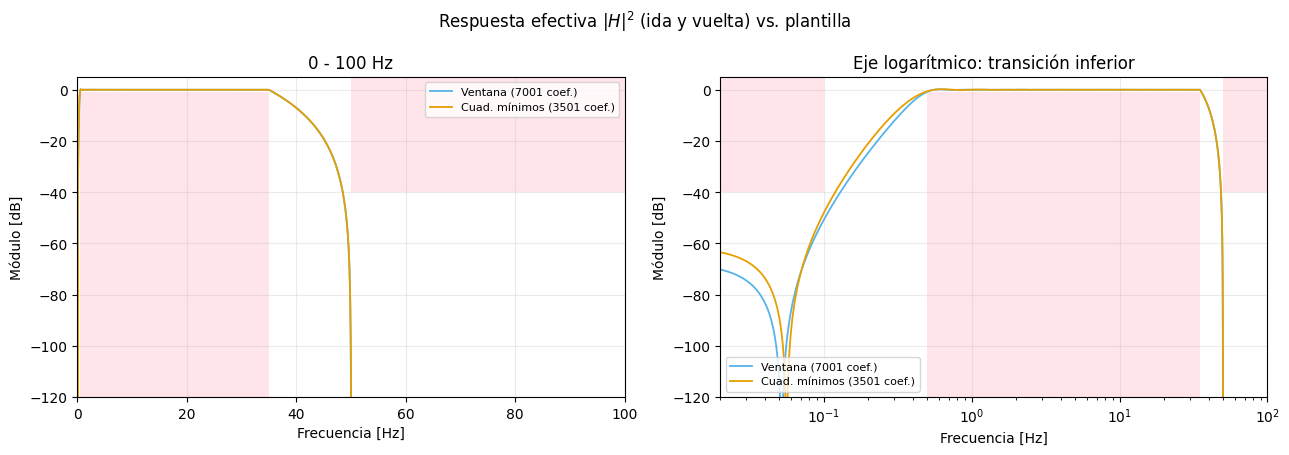

In [11]:
def dibujar_plantilla(ax, piso=-120):
    kw = dict(color='#FFB6C1', alpha=0.35, lw=0)
    ax.fill_between([1e-4, ws1], -atenuacion, 10, **kw)
    ax.fill_between([wp1, wp2], -ripple, piso, **kw)
    ax.fill_between([ws2, nyq_frec], -atenuacion, 10, **kw)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
fig.suptitle('Respuesta efectiva $|H|^2$ (ida y vuelta) vs. plantilla', fontsize=12)
for ax, (xlim, escala) in zip(axes, [((0, 100), 'linear'), ((0.02, 100), 'log')]):
    for nombre, H in H_ef.items():
        ax.plot(f_eval, H, lw=1.3, color=COL[nombre], label=f'{nombre} ({len(filtros[nombre])} coef.)')
    dibujar_plantilla(ax)
    ax.set(xscale=escala, xlim=xlim, ylim=(-120, 5), xlabel='Frecuencia [Hz]', ylabel='Módulo [dB]')
    ax.legend(fontsize=8, loc='lower left' if escala == 'log' else 'upper right')
axes[0].set_title('0 - 100 Hz')
axes[1].set_title('Eje logarítmico: transición inferior')
plt.tight_layout()
plt.show()

## Aplicación al ECG

Filtrar ida y vuelta con $h[n]$ equivale a convolucionar una vez con $h[n] * h[-n]$, que se hace por FFT (`oaconvolve`). Los extremos se extienden por reflexión para evitar transitorios.

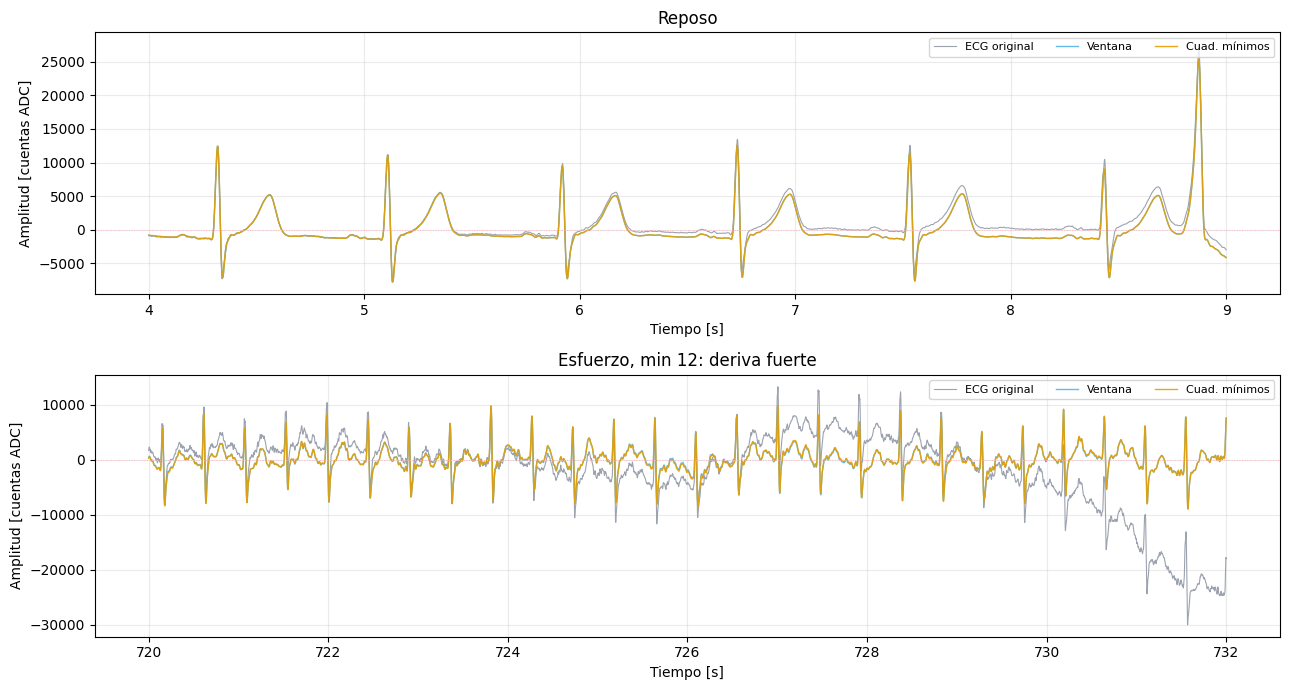

In [12]:
def filtfilt_fir(b, x):
    h2  = np.convolve(b, b[::-1])   # respuesta |H|^2 de fase cero
    pad = len(b)
    xp  = np.pad(x, pad, mode='reflect')
    return sig.oaconvolve(xp, h2, mode='same')[pad:-pad]


ecg_f = {nombre: filtfilt_fir(b, ecg) for nombre, b in filtros.items()}

fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for ax, (titulo, (a, b)) in zip(axes, [('Reposo', (4000, 9000)),
                                       ('Esfuerzo, min 12: deriva fuerte', (720000, 732000))]):
    ax.plot(t[a:b], ecg[a:b] - np.median(ecg[a:b]), lw=0.8, color='#9ca3af', label='ECG original')
    for nombre, x in ecg_f.items():
        ax.plot(t[a:b], x[a:b], lw=1, color=COL[nombre], label=nombre, alpha=0.9)
    ax.axhline(0, color=COL_AUX, lw=0.7, ls=':')
    ax.set(title=titulo, xlabel='Tiempo [s]', ylabel='Amplitud [cuentas ADC]')
    ax.legend(fontsize=8, loc='upper right', ncol=4)
plt.tight_layout()
plt.show()

## Conclusión

Los tres métodos de `scipy.signal` cumplen la plantilla como pasabanda de una sola etapa. Los métodos óptimos (`firls` y `remez`) lo logran con la mitad de coeficientes que la ventana, pero exigen definir bien la transición superior: dejarla libre con un filtro tan largo hace que `firls` quede mal condicionado y que `remez` no converja.